# Chapitre 7 - Cours 4 : sérialisabilité, exécution en série, 2PL et SSI

Ce notebook couvre la section *Serializability* : *Actual Serial Execution*
(*Encapsulating transactions in stored procedures*, *Pros and cons of stored procedures*,
*Partitioning*, *Summary of serial execution*), *Two-Phase Locking (2PL)*
(*Implementation of two-phase locking*, *Performance of two-phase locking*, *Predicate
locks*, *Index-range locks*) et *Serializable Snapshot Isolation (SSI)* (*Pessimistic versus
optimistic concurrency control*, *Decisions based on an outdated premise*,
*Detecting stale MVCC reads*, *Detecting writes that affect prior reads*, *Performance of
serializable snapshot isolation*), ainsi que le résumé du chapitre.

**Plan.**

1. La sérialisabilité : définition et vérification (graphe de précédence).
2. Exécution réellement en série.
3. Procédures stockées et déterminisme.
4. Exécution en série et partitionnement.
5. Le verrouillage à deux phases (2PL).
6. Performance de 2PL.
7. Verrous de prédicat et verrous d'intervalle d'index.
8. L'isolation par instantané sérialisable (SSI).
9. Performance comparée : série, 2PL, SSI.

In [1]:
import itertools

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

from ddia import transactions as tr
from ddia.transactions import (R, W, S, INC, run, plot_history, plot_precedence, precedence_graph,
                               is_serializable, simulate_load, LEVEL_LABELS)
from ddia.diagrams import Diagram
from ddia.timelines import SpaceTime
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
# graduations des axes logarithmiques sans mathtext (la police du style n'a pas le signe moins)
LOGFMT = FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " ") if v >= 1 else f"{v:g}")
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. La sérialisabilité : définition et vérification (section *Serializability*)

Le bilan des cours 2 et 3 est sombre : les niveaux d'isolation sont difficiles à
comprendre et implémentés différemment selon les bases ; il est difficile de savoir, en
lisant le code, s'il est sûr à un niveau donné ; et il n'existe pas de bon outil pour
détecter les conditions de course. La réponse des chercheurs est la même depuis les
années 1970 : **utilisez l'isolation sérialisable**. Elle garantit que le résultat est le
même que si les transactions s'étaient exécutées **une par une**, dans un certain ordre :
si chaque transaction est correcte seule, elle l'est en concurrence.

**Comment vérifier qu'une exécution est sérialisable ?** Deux méthodes, implémentées dans
le module :

- par **force brute** (`is_serializable`) : comparer l'état final et les valeurs lues à
  ceux de chacun des $n!$ ordres série ;
- par le **graphe de précédence** (`precedence_graph`) : un sommet par transaction validée
  et un arc $T_i \to T_j$ quand une opération de $T_i$ doit précéder une opération en
  conflit de $T_j$ (même objet, au moins une écriture) : $T_j$ lit ce que $T_i$ a écrit
  (`wr`), $T_j$ écrase ce que $T_i$ a écrit (`ww`), ou $T_j$ écrase ce que $T_i$ avait lu
  (`rw`, anti-dépendance). Si ce graphe est **acyclique**, tout ordre topologique est un
  ordre série équivalent (sérialisabilité **par conflits**, un peu plus stricte que la
  force brute).

Appliquons les deux méthodes aux 20 entrelacements des médecins de garde (cours 3), sans
aucune isolation.

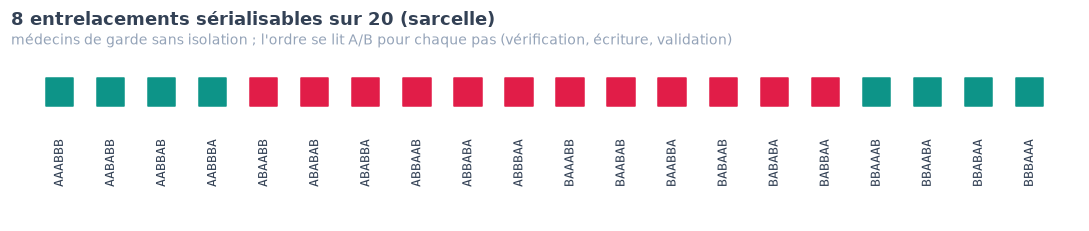

Les deux méthodes concordent : True


In [2]:
GARDE = {"alice": True, "bruno": True}


def se_retire(moi):
    def prog():
        presents = yield S(lambda k, v: v is True, "de garde ?")
        if len(presents) >= 2:
            yield W(moi, False)
    return prog


progs = {"A": se_retire("alice"), "B": se_retire("bruno")}
lignes = []
for pos in itertools.combinations(range(6), 3):
    ordre = ["A" if i in pos else "B" for i in range(6)]
    r = run(GARDE, progs, ordre, level="none")
    lignes.append(dict(ordre="".join(ordre),
                       sérialisable=is_serializable(r, GARDE, progs) is not None,
                       graphe_acyclique=nx.is_directed_acyclic_graph(precedence_graph(r)),
                       médecins_de_garde=sum(r.final.values())))
ent = pd.DataFrame(lignes)
fig, ax = plt.subplots(figsize=(10, 2.2))
ax.scatter(range(20), np.zeros(20), s=320, marker="s",
           c=[TEAL if v else ROSE for v in ent["sérialisable"]])
for i, o in enumerate(ent["ordre"]):
    ax.text(i, -0.55, o, rotation=90, ha="center", va="top", fontsize=8.5, family="monospace")
ax.set_ylim(-1.5, 0.5); ax.set_yticks([]); ax.set_xticks([])
ax.grid(False)
for s_ in ("left", "bottom"):
    ax.spines[s_].set_visible(False)
ax.set_title(f"{ent['sérialisable'].sum()} entrelacements sérialisables sur 20 (sarcelle)")
subtitle(ax, "médecins de garde sans isolation ; l'ordre se lit A/B pour chaque pas (vérification, écriture, validation)")
plt.tight_layout(); plt.show()
print("Les deux méthodes concordent :", (ent["sérialisable"] == ent["graphe_acyclique"]).all())

Seuls les entrelacements où l'une des transactions **vérifie après** l'écriture de
l'autre sont sérialisables (et laissent un médecin de garde) ; sans aucune isolation, il
suffit que l'écriture ait eu lieu, même non validée. Les deux tests concordent
ici. Un ordonnanceur sérialisable doit donc refuser (faire attendre, ou abandonner) toutes
les exécutions qui créeraient un cycle. Les bases utilisent trois techniques : l'exécution
réellement en série, le verrouillage à deux phases, et le contrôle optimiste (SSI).

> **À retenir.** Sérialisable = équivalent à **un** ordre série. On le vérifie par un
> graphe de précédence acyclique ; un cycle signale une anomalie.